# Cap. 3: Analisis Exploratorio de Datos

Este notebook corresponde al **Capitulo 3** de la tesis.

## Objetivos
1. Cargar datos historicos de BTC (y ETH para validacion)
2. Visualizar series de precios y log-retornos
3. Documentar hechos estilizados: colas pesadas, clustering, asimetria
4. Tests de estacionaridad (ADF/KPSS)
5. Analisis por ventanas temporales (regimenes)
6. Seleccionar frecuencia optima para estimacion del modelo SV

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('../..'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from tesis.data.loader import load_price_series, compute_log_returns, split_train_test

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11

## 1. Carga de Datos

In [2]:
# Cargar BTC a diferentes frecuencias
btc_1min = load_price_series(asset='BTC', resample_rule=None)
btc_1h = load_price_series(asset='BTC', resample_rule='1h')
btc_1d = load_price_series(asset='BTC', resample_rule='1D')

print(f'BTC 1min: {len(btc_1min):,} observaciones, {btc_1min.index.min()} -> {btc_1min.index.max()}')
print(f'BTC 1h:   {len(btc_1h):,} observaciones')
print(f'BTC 1D:   {len(btc_1d):,} observaciones')

# ETH para validacion posterior
eth_1d = load_price_series(asset='ETH', resample_rule='1D')
print(f'ETH 1D:   {len(eth_1d):,} observaciones')

BTC 1min: 7,512,170 observaciones, 2012-01-01 10:01:00 -> 2026-04-15 00:10:00
BTC 1h:   125,205 observaciones
BTC 1D:   5,219 observaciones


ETH 1D:   3,064 observaciones


## 2. Series de Precios

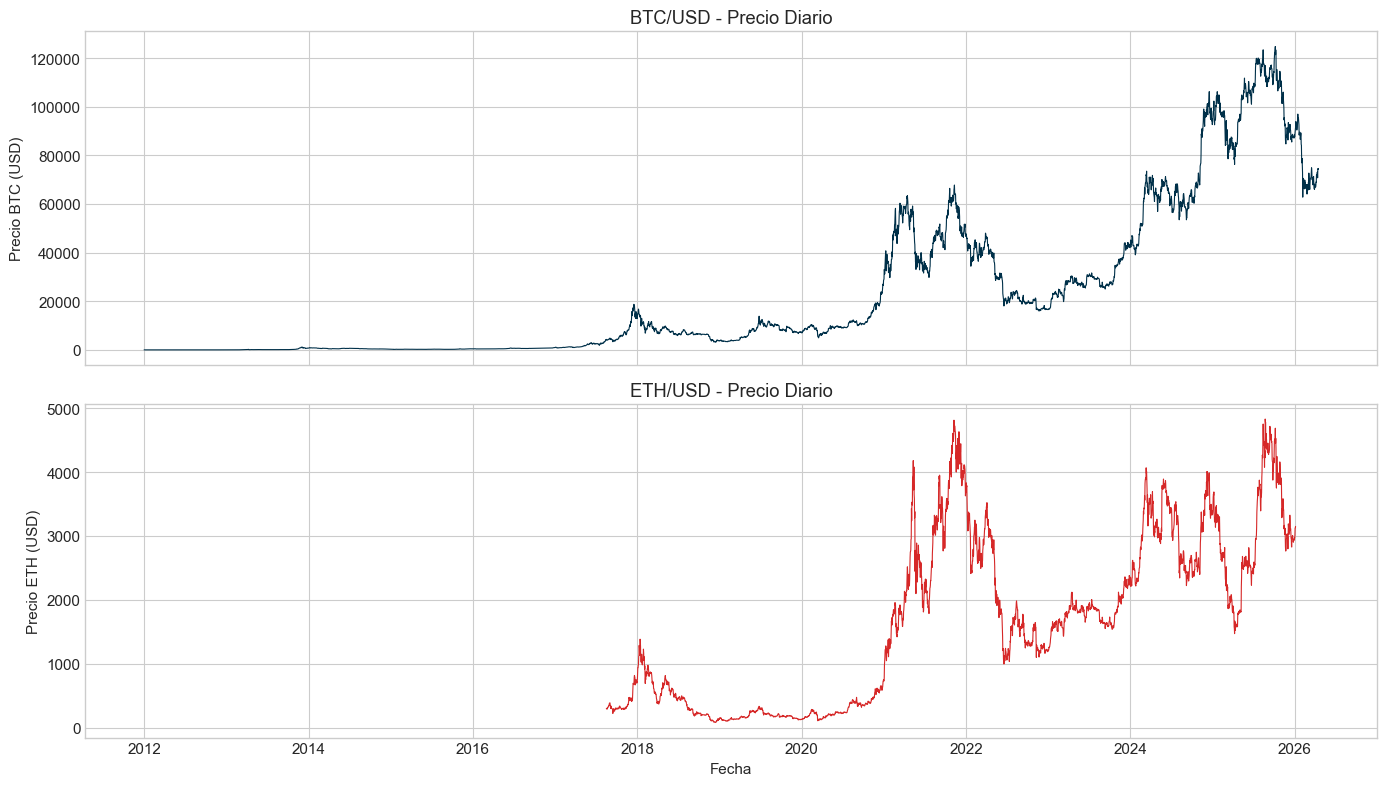

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(btc_1d.index, btc_1d.values, color='#003049', linewidth=0.8)
axes[0].set_ylabel('Precio BTC (USD)')
axes[0].set_title('BTC/USD - Precio Diario')

axes[1].plot(eth_1d.index, eth_1d.values, color='#d62828', linewidth=0.8)
axes[1].set_ylabel('Precio ETH (USD)')
axes[1].set_title('ETH/USD - Precio Diario')
axes[1].set_xlabel('Fecha')

plt.tight_layout()
plt.show()

## 3. Log-Retornos Diarios

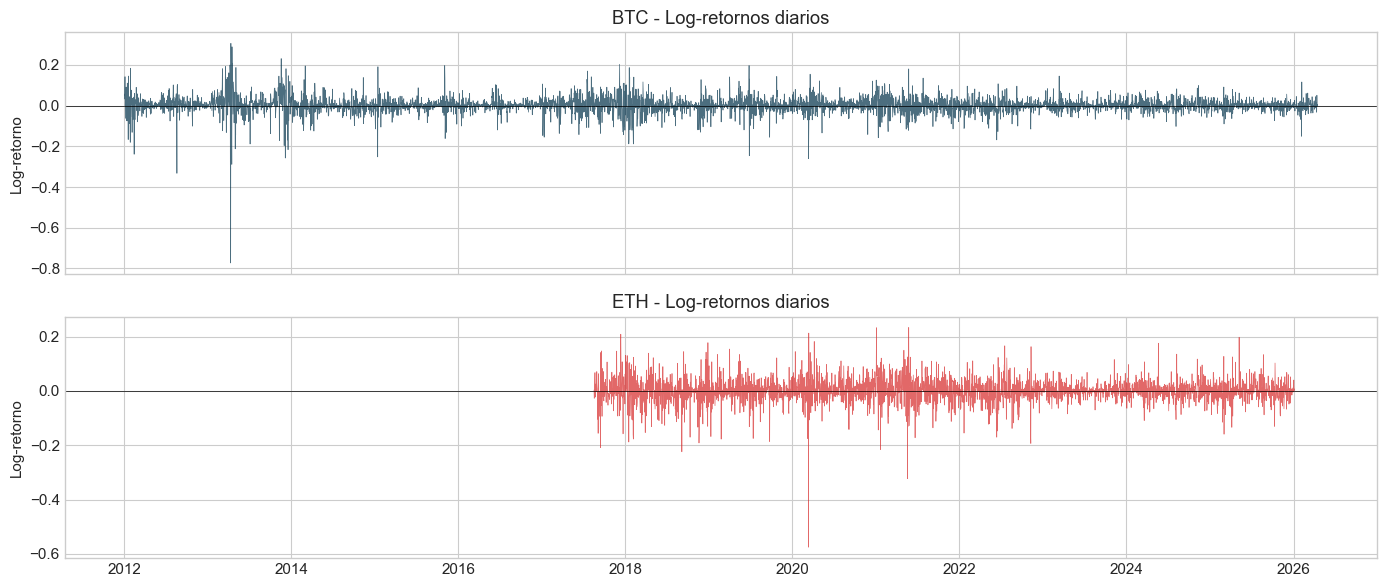


--- Estadisticas descriptivas BTC ---
Media:    0.001848
Std:      0.041434
Skewness: -1.9333
Kurtosis: 36.4575  (exceso, Normal=0)
Min:      -0.7730
Max:      0.3061


In [4]:
r_btc = compute_log_returns(btc_1d)
r_eth = compute_log_returns(eth_1d)

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)

axes[0].plot(r_btc.index, r_btc.values, color='#003049', linewidth=0.5, alpha=0.7)
axes[0].set_ylabel('Log-retorno')
axes[0].set_title('BTC - Log-retornos diarios')
axes[0].axhline(0, color='k', linewidth=0.5)

axes[1].plot(r_eth.index, r_eth.values, color='#d62828', linewidth=0.5, alpha=0.7)
axes[1].set_ylabel('Log-retorno')
axes[1].set_title('ETH - Log-retornos diarios')
axes[1].axhline(0, color='k', linewidth=0.5)

plt.tight_layout()
plt.show()

print('\n--- Estadisticas descriptivas BTC ---')
print(f'Media:    {r_btc.mean():.6f}')
print(f'Std:      {r_btc.std():.6f}')
print(f'Skewness: {r_btc.skew():.4f}')
print(f'Kurtosis: {r_btc.kurtosis():.4f}  (exceso, Normal=0)')
print(f'Min:      {r_btc.min():.4f}')
print(f'Max:      {r_btc.max():.4f}')

## 4. Hechos Estilizados

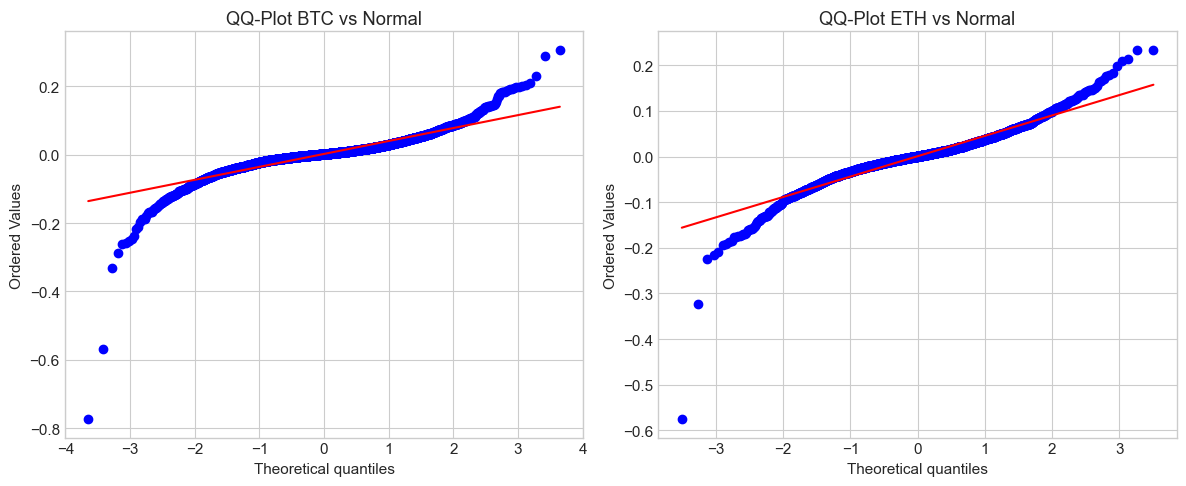

Jarque-Bera BTC: stat=291655.77, p-value=0.00e+00
Jarque-Bera ETH: stat=15599.72, p-value=0.00e+00


In [5]:
# 4.1 QQ-Plot vs Normal
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

stats.probplot(r_btc.values, dist='norm', plot=axes[0])
axes[0].set_title('QQ-Plot BTC vs Normal')

stats.probplot(r_eth.values, dist='norm', plot=axes[1])
axes[1].set_title('QQ-Plot ETH vs Normal')

plt.tight_layout()
plt.show()

# Jarque-Bera test
jb_btc = stats.jarque_bera(r_btc.values)
jb_eth = stats.jarque_bera(r_eth.values)
print(f'Jarque-Bera BTC: stat={jb_btc.statistic:.2f}, p-value={jb_btc.pvalue:.2e}')
print(f'Jarque-Bera ETH: stat={jb_eth.statistic:.2f}, p-value={jb_eth.pvalue:.2e}')

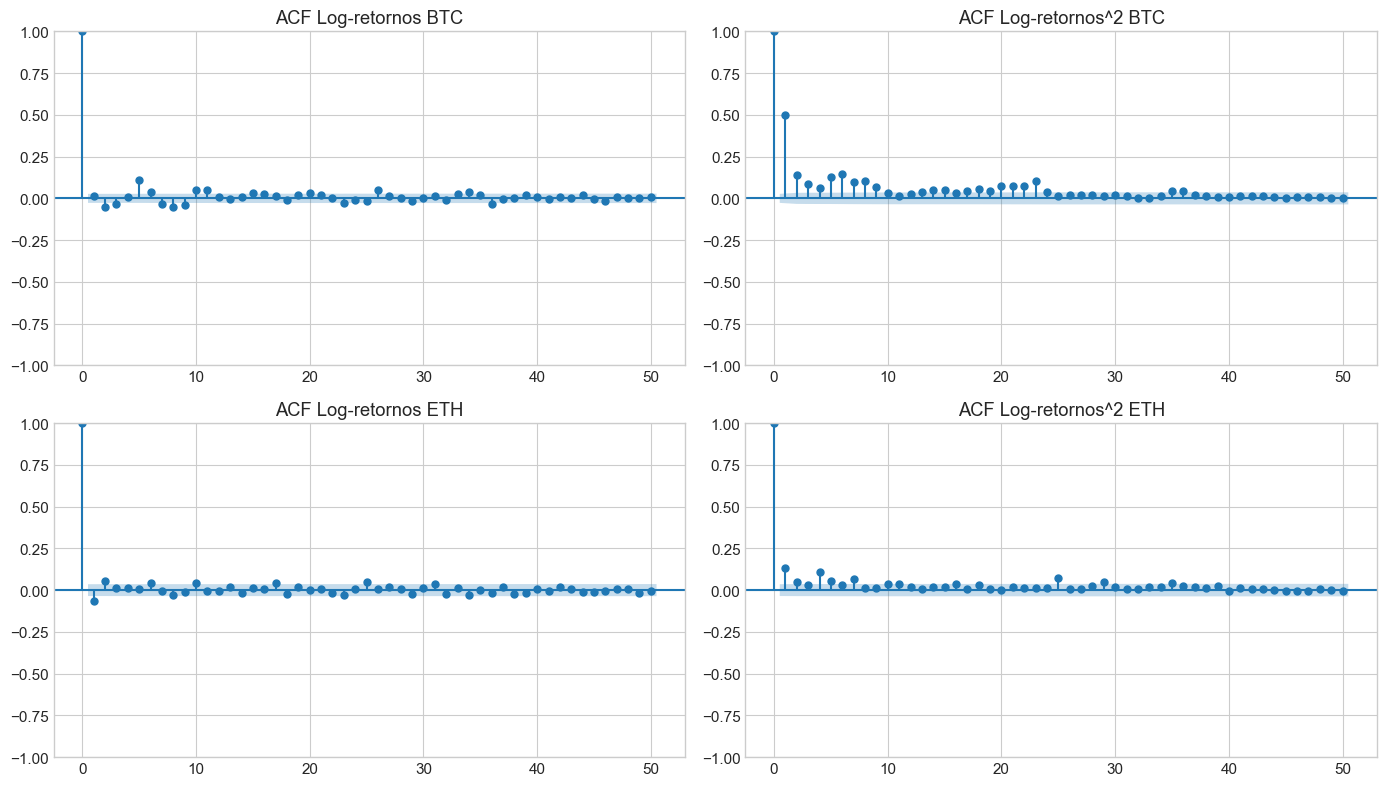

Si r_t tiene ACF insignificante pero r_t^2 tiene ACF significativa,
esto evidencia clustering de volatilidad -> motivacion para modelo SV.


In [6]:
# 4.2 Clustering de volatilidad: ACF de retornos vs retornos^2
from statsmodels.graphics.tsaplots import plot_acf

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

plot_acf(r_btc.values, lags=50, ax=axes[0, 0], title='ACF Log-retornos BTC')
plot_acf(r_btc.values**2, lags=50, ax=axes[0, 1], title='ACF Log-retornos^2 BTC')
plot_acf(r_eth.values, lags=50, ax=axes[1, 0], title='ACF Log-retornos ETH')
plot_acf(r_eth.values**2, lags=50, ax=axes[1, 1], title='ACF Log-retornos^2 ETH')

plt.tight_layout()
plt.show()

print('Si r_t tiene ACF insignificante pero r_t^2 tiene ACF significativa,')
print('esto evidencia clustering de volatilidad -> motivacion para modelo SV.')

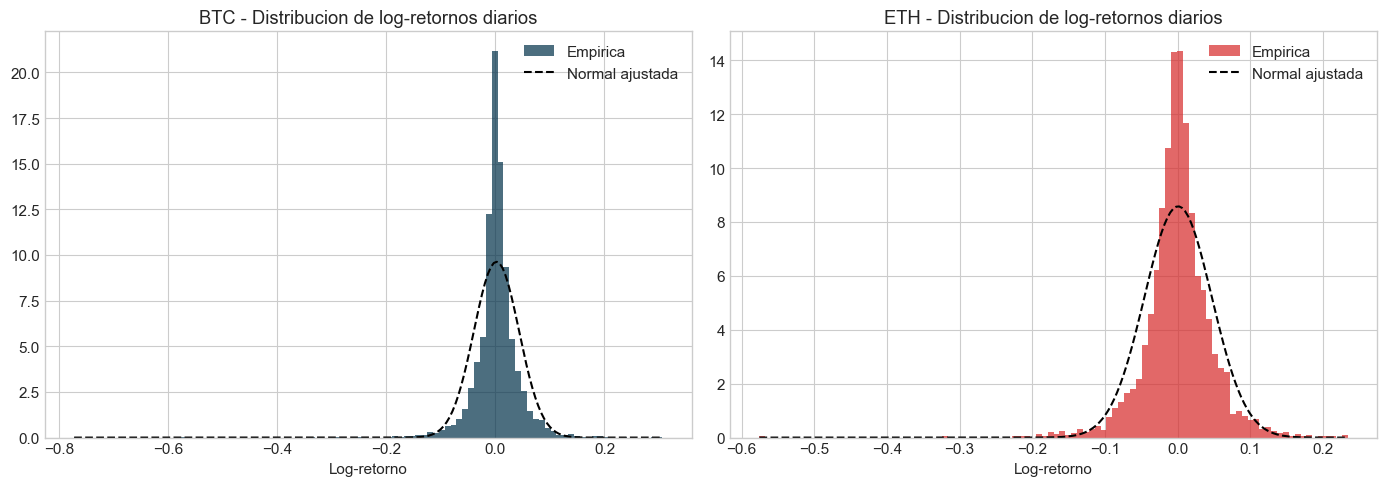

In [7]:
# 4.3 Distribucion empirica vs Normal
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, r, name, color in [(axes[0], r_btc, 'BTC', '#003049'), (axes[1], r_eth, 'ETH', '#d62828')]:
    ax.hist(r.values, bins=100, density=True, alpha=0.7, color=color, label='Empirica')
    x = np.linspace(r.min(), r.max(), 200)
    ax.plot(x, stats.norm.pdf(x, r.mean(), r.std()), 'k--', linewidth=1.5, label='Normal ajustada')
    ax.set_title(f'{name} - Distribucion de log-retornos diarios')
    ax.set_xlabel('Log-retorno')
    ax.legend()

plt.tight_layout()
plt.show()

## 5. Tests de Estacionaridad

In [8]:
from statsmodels.tsa.stattools import adfuller, kpss

# ADF test (H0: raiz unitaria, queremos rechazar)
adf_result = adfuller(r_btc.values, autolag='AIC')
print('=== ADF Test BTC log-retornos ===')
print(f'Estadistico: {adf_result[0]:.4f}')
print(f'p-value: {adf_result[1]:.6f}')
print(f'Lags usados: {adf_result[2]}')
print(f'Conclusion: {"Rechazamos H0 -> estacionario" if adf_result[1] < 0.05 else "No rechazamos H0"}')

# KPSS test (H0: estacionario, queremos NO rechazar)
print('\n=== KPSS Test BTC log-retornos ===')
kpss_result = kpss(r_btc.values, regression='c', nlags='auto')
print(f'Estadistico: {kpss_result[0]:.4f}')
print(f'p-value: {kpss_result[1]:.4f}')
print(f'Conclusion: {"No rechazamos H0 -> estacionario" if kpss_result[1] > 0.05 else "Rechazamos H0 -> no estacionario"}')

=== ADF Test BTC log-retornos ===
Estadistico: -10.6095
p-value: 0.000000
Lags usados: 33
Conclusion: Rechazamos H0 -> estacionario

=== KPSS Test BTC log-retornos ===
Estadistico: 0.4069
p-value: 0.0742
Conclusion: No rechazamos H0 -> estacionario


## 6. Analisis por Ventanas Temporales (Regimenes)

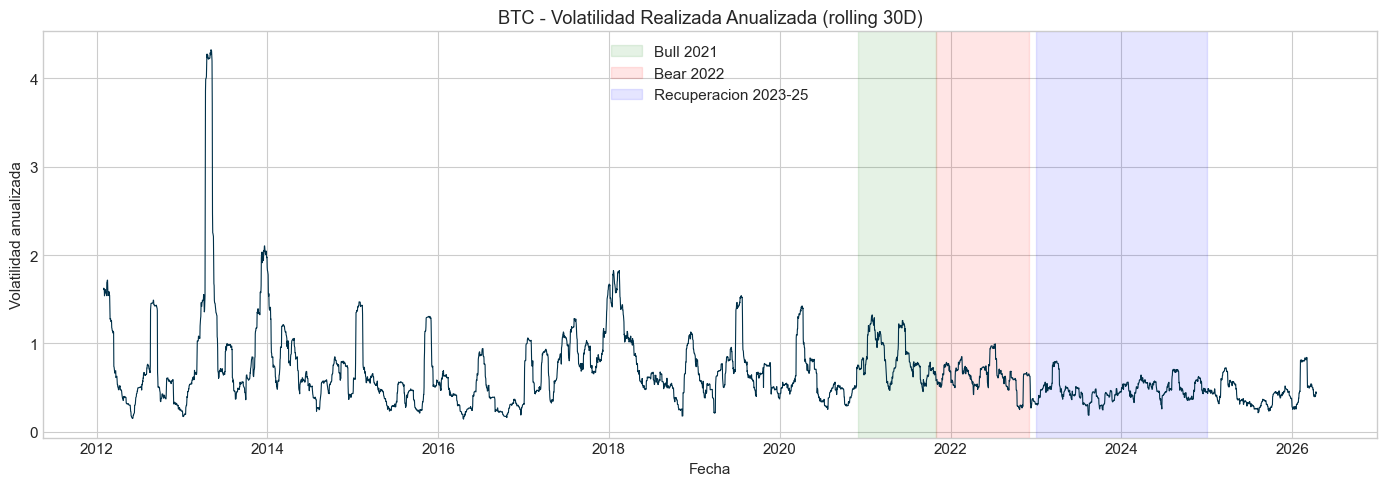


--- Bull 2021 ---
  N obs:     336
  Media:     0.003467
  Std:       0.044847
  Vol anual: 0.8568
  Kurtosis:  1.3203

--- Bear 2022 ---
  N obs:     396
  Media:     -0.003225
  Std:       0.033848
  Vol anual: 0.6467
  Kurtosis:  3.1557

--- Recovery 2023-25 ---
  N obs:     732
  Media:     0.002377
  Std:       0.025468
  Vol anual: 0.4866
  Kurtosis:  2.6537


In [9]:
# Volatilidad realizada (rolling 30 dias)
vol_30d = r_btc.rolling(30).std() * np.sqrt(365)  # anualizada

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(vol_30d.index, vol_30d.values, color='#003049', linewidth=0.8)
ax.set_title('BTC - Volatilidad Realizada Anualizada (rolling 30D)')
ax.set_ylabel('Volatilidad anualizada')
ax.set_xlabel('Fecha')

# Marcar periodos
ax.axvspan('2020-12-01', '2021-11-01', alpha=0.1, color='green', label='Bull 2021')
ax.axvspan('2021-11-01', '2022-12-01', alpha=0.1, color='red', label='Bear 2022')
ax.axvspan('2023-01-01', '2025-01-01', alpha=0.1, color='blue', label='Recuperacion 2023-25')
ax.legend()

plt.tight_layout()
plt.show()

# Estadisticas por periodo
periods = {
    'Bull 2021': ('2020-12-01', '2021-11-01'),
    'Bear 2022': ('2021-11-01', '2022-12-01'),
    'Recovery 2023-25': ('2023-01-01', '2025-01-01'),
}

for name, (start, end) in periods.items():
    r_period = r_btc.loc[start:end]
    print(f'\n--- {name} ---')
    print(f'  N obs:     {len(r_period)}')
    print(f'  Media:     {r_period.mean():.6f}')
    print(f'  Std:       {r_period.std():.6f}')
    print(f'  Vol anual: {r_period.std() * np.sqrt(365):.4f}')
    print(f'  Kurtosis:  {r_period.kurtosis():.4f}')

## 7. Seleccion de Frecuencia para Modelo SV

Comparar propiedades de retornos a 1min, 1h y 1D.
**Conclusiones esperadas:**
- Retornos diarios son los mas limpios para estimacion del modelo SV.
- Menor ruido de microestructura.
- Suficientes observaciones (~1800).

In [10]:
r_1min = compute_log_returns(btc_1min)
r_1h = compute_log_returns(btc_1h)
r_1d = r_btc  # ya calculado

for name, r in [('1 min', r_1min), ('1 hora', r_1h), ('1 dia', r_1d)]:
    print(f'\n--- Retornos {name} ---')
    print(f'  N:         {len(r):,}')
    print(f'  Media:     {r.mean():.8f}')
    print(f'  Std:       {r.std():.8f}')
    print(f'  Kurtosis:  {r.kurtosis():.2f}')
    print(f'  Skewness:  {r.skew():.4f}')


--- Retornos 1 min ---
  N:         7,512,169
  Media:     0.00000129
  Std:       0.00176493
  Kurtosis:  6929.75
  Skewness:  3.8618

--- Retornos 1 hora ---
  N:         125,204
  Media:     0.00007746
  Std:       0.00968005
  Kurtosis:  114.98
  Skewness:  -1.2146

--- Retornos 1 dia ---
  N:         5,218
  Media:     0.00184801
  Std:       0.04143422
  Kurtosis:  36.46
  Skewness:  -1.9333


## 8. Train/Test Split

Definimos el split temporal para validacion posterior (Capitulo 8).

In [11]:
btc_train, btc_test = split_train_test(btc_1d, split_date='2024-01-01')

print(f'Train: {len(btc_train)} obs, {btc_train.index.min()} -> {btc_train.index.max()}')
print(f'Test:  {len(btc_test)} obs, {btc_test.index.min()} -> {btc_test.index.max()}')

r_train = compute_log_returns(btc_train)
r_test = compute_log_returns(btc_test)

print(f'\nRetornos train: N={len(r_train)}, std={r_train.std():.6f}')
print(f'Retornos test:  N={len(r_test)}, std={r_test.std():.6f}')

Train: 4383 obs, 2012-01-01 00:00:00 -> 2023-12-31 00:00:00
Test:  836 obs, 2024-01-01 00:00:00 -> 2026-04-15 00:00:00

Retornos train: N=4382, std=0.043845
Retornos test:  N=835, std=0.025286
